In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

from objective_function import objective_function

# Loading 

In [2]:
cwd=Path.cwd()
raw_paths= list((cwd).glob("*.npy"))

file_paths= sorted(
    raw_paths,
    key= lambda p: int(p.stem.split("_")[2])
)

iter_list=[np.load(file,allow_pickle=True).item() for file in file_paths]

In [3]:
field_data_path=cwd.parent.parent.parent/"STIMTEC_example/BH10_20180718_40.6_SR_v2.csv"
field_data=pd.read_csv(field_data_path,header=0)
#protocols
#v1

pro_v1=pd.read_csv(cwd.parent.parent.parent/"STIMTEC_example/protocol_SR.csv",header=0)
pro_v2=pd.read_csv(cwd.parent.parent.parent/"STIMTEC_example/protocol_SR_v2.csv",header=0)

#sampling
sampling_path = cwd.parent.parent/"lhoat_samples_manifestv16t2.csv"
sampling_data = pd.read_csv(sampling_path, header= 0)

# functions and processing

In [4]:
def get_shaded_area(t_initial: pd.Series, t_final: pd.Series, list_results: list[dict]) -> np.array:
    "Returns  time, lower, and upper bounds with shaed area of curves"
    "Note: adapt the input results, here list[dict]"

    t_common = np.linspace(t_initial, t_final, int(t_final - t_initial) )
    p_matrix = np.array([
        np.interp(t_common, p_t["timevalues"], p_t["values"]) for p_t in list_results
    ])

    p_fused_lower = np.min(p_matrix, axis=0)
    p_fused_upper = np.max(p_matrix, axis=0)

    return t_common, p_fused_lower, p_fused_upper


def finding_best_run(list_results: list[dict], sampling_data: pd.DataFrame) -> None:
    """Return the best dict of list[dict] of results"""

    best_run=sampling_data.loc[[ int(np.argmin(sampling_data["RMSE"])) ]]
    results = np.array(iter_list)
   
    best_run_pt= results[int(best_run["run_id"].iloc[0])].copy()
    best_metadata=best_run[["L","sf0","s_plat","pst","ws", "RMSE"]]

    print(f"Mininum cost RMSE: \n{best_metadata[['RMSE']]}")
    print(f"Best metadata: \n{best_metadata}")
    print(f"Best run_id: \n{best_run[["run_id"]]}")

    return best_run_pt, best_metadata
    

In [5]:
#adding cost
RMSE = []
for value in iter_list:
    rmse = objective_function(value, field_data)
    RMSE.append(rmse)

RMSE = pd.Series(RMSE,name = "RMSE")

sampling_data= sampling_data.iloc[:len(RMSE),:]
sampling_data = pd.concat([sampling_data, RMSE], axis=1)



In [6]:
#getting shade area and bes fit

t_common, p_fused_lower, p_fused_upper = get_shaded_area(field_data["Zeit [s]"].min(), field_data["Zeit [s]"].max(), iter_list)
best_run, best_metadata = finding_best_run(iter_list, sampling_data)

Mininum cost RMSE: 
             RMSE
108  1.170201e+06
Best metadata: 
           L           sf0        s_plat           pst            ws  \
108  1.51573  6.362470e-08  5.000000e-08  3.620402e+06  1.057873e+06   

             RMSE  
108  1.170201e+06  
Best run_id: 
     run_id
108     108


# Visualization of sampling/results

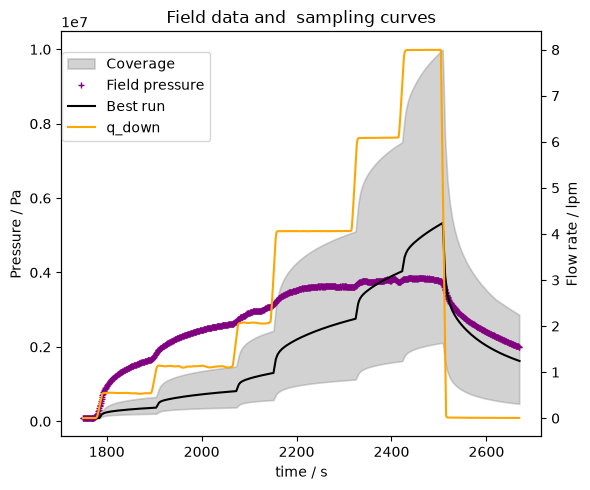

In [ ]:
fig0, axs = plt.subplots( figsize = [6,5], sharex= True)

axs1=axs.twinx()
axs.set_ylabel("Pressure / Pa")
axs.set_xlabel("time / s")
axs1.set_ylabel("Flow rate / lpm")

axs.fill_between(
    t_common,
    p_fused_lower,
    p_fused_upper,
    color = "tab:gray",
    alpha = 0.35,
    edgecolor = "tab:gray",
    lw = 1.2,
    label= "Coverage"
)

axs1.plot(field_data["Zeit [s]"], field_data["Q_downhole [lpm]_s"],label="q_down ",  color="orange")

axs.plot(field_data["Zeit [s]"],
         field_data["Pint_downhole [MPa]_s"]*1e6,
         ls= "", marker = "+", ms = 5, label="Field pressure",color='purple' )

axs.plot(best_run["timevalues"],
         best_run["values"],
         label="Best run",color='k' )

plt.title("Field data and  sampling curves")

fig0.legend(loc= "upper left", bbox_to_anchor=(0.1, 0.9))
# axs.grid(True, alpha = 0.3)

plt.tight_layout()
plt.show()

#fig0.savefig("rf_v16t2_BH10_40_6.pdf",format="pdf",bbox_inches='tight',pad_inches=0.02)

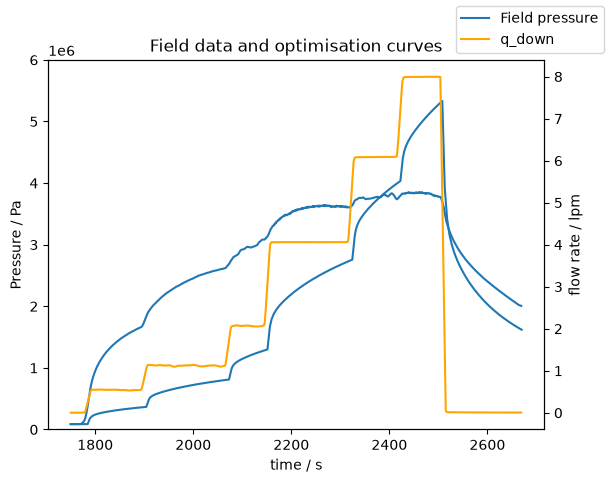

In [ ]:
fig, ax= plt.subplots(sharex=True)
ax1=ax.twinx()
ax.set_ylabel("Pressure / Pa")
ax.set_xlabel("time / s")
ax1.set_ylabel("flow rate / lpm")
for budle in iter_list:
    ax.plot(budle["timevalues"],budle["values"])

ax.plot(field_data["Zeit [s]"], field_data["Pint_downhole [MPa]_s"]*1e6,label="Field pressure",color='tab:blue' )
ax1.plot(field_data["Zeit [s]"], field_data["Q_downhole [lpm]_s"],label="q_down ",  color="orange")
#ax1.step(qarra2[0],qarra2[1],label="v2") #in m3/s

# for i in range(len(pro_v1)):
#     plt.axvline(pro_v1.loc[i,'T_s [s]'],ls="--",color="k")

# for j in range(len(pro_v2)):    
#     plt.axvline(pro_v2.loc[j,'T_s'],ls="--",color="tab:blue",label="q prot")
ax.set_ylim(0,6e6)
plt.title("Field data and optimisation curves")
fig.legend()
plt.pause(1)




In [9]:
iter_list[0].keys()

dict_keys(['values', 'timevalues', 'metadata'])

In [10]:
for value in iter_list:
    print(value['metadata'])

{'variable_name': 'pressure', 'unit': 'Pa', 'time_unit': 's', 'coordinates': array([[ 3.80e-02, -4.06e+01,  1.00e-18]]), 'source_file': '_out_t\\run\\BH10_20180718_40.6.pvd'}
{'variable_name': 'pressure', 'unit': 'Pa', 'time_unit': 's', 'coordinates': array([[ 3.80e-02, -4.06e+01,  1.00e-18]]), 'source_file': '_out_t\\run\\BH10_20180718_40.6.pvd'}
{'variable_name': 'pressure', 'unit': 'Pa', 'time_unit': 's', 'coordinates': array([[ 3.80e-02, -4.06e+01,  1.00e-18]]), 'source_file': '_out_t\\run\\BH10_20180718_40.6.pvd'}
{'variable_name': 'pressure', 'unit': 'Pa', 'time_unit': 's', 'coordinates': array([[ 3.80e-02, -4.06e+01,  1.00e-18]]), 'source_file': '_out_t\\run\\BH10_20180718_40.6.pvd'}
{'variable_name': 'pressure', 'unit': 'Pa', 'time_unit': 's', 'coordinates': array([[ 3.80e-02, -4.06e+01,  1.00e-18]]), 'source_file': '_out_t\\run\\BH10_20180718_40.6.pvd'}
{'variable_name': 'pressure', 'unit': 'Pa', 'time_unit': 's', 'coordinates': array([[ 3.80e-02, -4.06e+01,  1.00e-18]]), 'sou

In [11]:
#saving the csv data
df=[]
for value in iter_list:
    df.append(value['metadata'])

# df_=pd.DataFrame(df)
# df_.to_csv("opt_val_bh10_40_6_run_v15.csv",index=False)

